# Lab 01 - Transformer Attention & SFT Loss Masking

**Goal:** implement scaled dot-product attention with a causal mask from scratch, verify its invariants, and show
why supervised fine-tuning (SFT) masks prompt tokens with `ignore_index=-100` so that only the assistant response is learned.

Context: in the HR assistant, SFT data are (system + user prompt, assistant answer) pairs. Training on the prompt tokens
would teach the model to *generate user questions* and to imitate injected text - the loss must cover the answer only.

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
def show(fig, name):
    fig.tight_layout(); fig.savefig(name, dpi=110); plt.close(fig); display(Image(name))


## 1. Scaled dot-product attention

$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$, with $M_{ij}=-\infty$ for $j>i$ (causal).

In [2]:
def attention(Q, K, V, causal=True):
    d_k = Q.shape[-1]
    scores = Q @ K.swapaxes(-1, -2) / np.sqrt(d_k)
    if causal:
        T = scores.shape[-1]
        scores = np.where(np.triu(np.ones((T, T), dtype=bool), k=1), -np.inf, scores)
    scores = scores - scores.max(-1, keepdims=True)
    w = np.exp(scores)
    w = w / w.sum(-1, keepdims=True)
    return w @ V, w

tokens = ["<s>", "Wie", "lange", "dauert", "die", "Probezeit", "?"]
T, d_model, n_heads = len(tokens), 16, 4
X = rng.normal(size=(T, d_model))
Wq, Wk, Wv = (rng.normal(scale=d_model**-0.5, size=(d_model, d_model)) for _ in range(3))
out, W = attention(X @ Wq, X @ Wk, X @ Wv)
print("rows sum to 1:", np.allclose(W.sum(-1), 1.0))
print("no attention to the future:", np.allclose(np.triu(W, k=1), 0.0))
print("first token attends only to itself:", W[0, 0])

rows sum to 1: True
no attention to the future: True
first token attends only to itself: 1.0


output shape: (7, 16) | per-head weights: (4, 7, 7)
matches torch.scaled_dot_product_attention: True


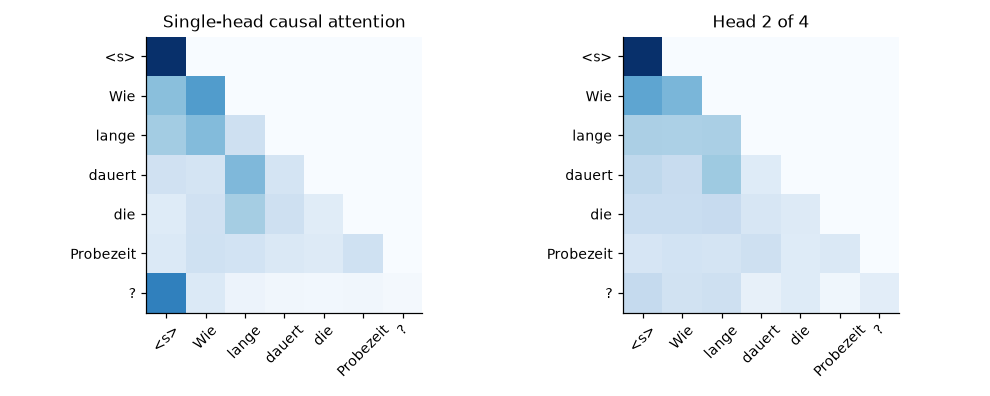

In [3]:
# Multi-head attention = split d_model into heads, attend independently, concatenate.
def multi_head(X, n_heads):
    T, d = X.shape
    dh = d // n_heads
    q, k, v = ((X @ W).reshape(T, n_heads, dh).transpose(1, 0, 2) for W in (Wq, Wk, Wv))
    o, w = attention(q, k, v)
    return o.transpose(1, 0, 2).reshape(T, d), w

mh_out, mh_w = multi_head(X, n_heads)
print("output shape:", mh_out.shape, "| per-head weights:", mh_w.shape)

# Cross-check against PyTorch's fused implementation
q = torch.tensor((X @ Wq)[None, None]); k = torch.tensor((X @ Wk)[None, None]); v = torch.tensor((X @ Wv)[None, None])
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)[0, 0].numpy()
print("matches torch.scaled_dot_product_attention:", np.allclose(ref, out, atol=1e-10))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].imshow(W, cmap="Blues"); axes[0].set_title("Single-head causal attention")
axes[1].imshow(mh_w[1], cmap="Blues"); axes[1].set_title("Head 2 of 4")
for ax in axes:
    ax.set_xticks(range(T)); ax.set_xticklabels(tokens, rotation=45); ax.set_yticks(range(T)); ax.set_yticklabels(tokens)
show(fig, "lab01_attention.png")

## 2. SFT loss masking with `ignore_index=-100`

Labels are the input ids shifted by one; every label that belongs to the prompt (or padding) is replaced with `-100`.
`F.cross_entropy(..., ignore_index=-100)` then averages only over response tokens.

In [4]:
vocab = ["<pad>", "<s>", "<user>", "<assistant>", "Wie", "lange", "dauert", "die", "Probezeit", "?", "Sie", "beträgt", "6", "Monate", ".", "</s>"]
tok = {w: i for i, w in enumerate(vocab)}
prompt = ["<s>", "<user>", "Wie", "lange", "dauert", "die", "Probezeit", "?", "<assistant>"]
answer = ["Sie", "beträgt", "6", "Monate", ".", "</s>"]
seq = prompt + answer + ["<pad>"] * 3
ids = torch.tensor([tok[w] for w in seq])
labels = ids[1:].clone()
inputs = ids[:-1]
n_prompt_labels = len(prompt) - 1          # predictions made while still inside the prompt
labels[:n_prompt_labels] = -100
labels[inputs.eq(tok["<pad>"]) | labels.eq(tok["<pad>"])] = -100
print("input :", [vocab[i] for i in inputs])
print("labels:", [vocab[i] if i >= 0 else "-100" for i in labels.tolist()])

logits = torch.randn(len(inputs), len(vocab), requires_grad=True, generator=torch.Generator().manual_seed(SEED))
masked = F.cross_entropy(logits, labels, ignore_index=-100)
per_tok = F.cross_entropy(logits, labels, ignore_index=-100, reduction="none")
manual = per_tok[labels != -100].mean()
unmasked = F.cross_entropy(logits, ids[1:])
print(f"masked loss {masked.item():.4f} == manual mean over response tokens {manual.item():.4f}")
print(f"unmasked loss (trains on prompt + padding too): {unmasked.item():.4f}")
masked.backward()
grad_rows = logits.grad.abs().sum(-1)
print("gradient on prompt positions is exactly zero:", bool(torch.all(grad_rows[:n_prompt_labels] == 0)))
print("number of positions receiving gradient:", int((grad_rows > 0).sum()), "= response tokens:", len(answer))

input : ['<s>', '<user>', 'Wie', 'lange', 'dauert', 'die', 'Probezeit', '?', '<assistant>', 'Sie', 'beträgt', '6', 'Monate', '.', '</s>', '<pad>', '<pad>']
labels: ['-100', '-100', '-100', '-100', '-100', '-100', '-100', '-100', 'Sie', 'beträgt', '6', 'Monate', '.', '</s>', '-100', '-100', '-100']
masked loss 3.1564 == manual mean over response tokens 3.1564
unmasked loss (trains on prompt + padding too): 3.1655
gradient on prompt positions is exactly zero: True
number of positions receiving gradient: 6 = response tokens: 6


## Takeaways
* The causal mask is what makes a decoder autoregressive; the check against `torch.scaled_dot_product_attention` confirms the math.
* With prompt masking, **zero gradient** flows from prompt tokens: the model learns *how to answer*, not how to reproduce
  user text (which could contain injected instructions or personal data - a data-minimisation argument under GDPR Art. 5).